# Assignment 1 — Part 04: výsledky simulácií

Jupyter verzia [RESULTS.md](RESULTS.md). Obsahuje vysvetlenia, šesť grafov,
tabuľky z nameraných dát a zistené obmedzenia. Grafy a tabuľky sú uložené aj
vo výstupoch notebooku, takže sú viditeľné už pri otvorení.

**Spustenie vo VS Code:** zvoľ kernel `.venv-jupyter/bin/python` a klikni
na **Run All**. Analýza používa existujúce súbory `figures/metrics.json`,
`RUN.json` a PNG grafy v repozitári. Dáta sú z letov **18. 10. 2026**.

Podklady k algoritmom a diagramom sú v [DESIGN.md](DESIGN.md).

In [1]:
# Copyright (c) 2026 STU FEI URK
# SPDX-License-Identifier: MIT

from pathlib import Path
import json
import math

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt

%matplotlib inline

relative = Path("assignment1_parts/04_documentation_and_defence")
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / relative / "figures/metrics.json").is_file()), None)
if root is None:
    raise FileNotFoundError("Otvor notebook v repozitári LRS-URK spolu s priečinkom figures.")
report = root / relative
figures = report / "figures"
metrics = json.loads((figures / "metrics.json").read_text(encoding="utf-8"))
run = json.loads((report / "RUN.json").read_text(encoding="utf-8"))
abort = run["abort"]


def number(value, digits=3):
    return f"{value:.{digits}f}".replace(".", ",")


def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def figure(name):
    display(Image(filename=str(figures / name), width=1100))


print(f"Načítané merania: {run['recording_date']}; zdroje: {figures.relative_to(root)}")

Načítané merania: 2026-10-18; zdroje: assignment1_parts/04_documentation_and_defence/figures


## Rozsah overenia

Merania vznikli **18. 10. 2026** spustením aktuálneho kódu v Gazebo Harmonic
8.15.0, ArduPilot SITL 4.7.0 (`1511f271`) a ROS 2 Jazzy/MAVROS. Použité boli
pôvodné svety `fei_lrs_gazebo.world` a `fei_lrs_outdoor.world`, mapa
`maps/FEI_LRS_PCD/map.pcd` a vnútorná misia `missions/exam_example.csv`.
Letová logika sa pri tvorbe grafov nemenila.

In [2]:
table(["Overenie", "Výsledok"], [
    ["Zostavenie v pracovnom adresári", run["checks"]["workspace_build"]],
    ["Zostavenie z čistej kópie zdrojov", run["checks"]["clean_source_copy_build"]],
    ["Regresné testy", f"{run['checks']['pytest']['passed']} úspešných"],
    ["Vnútorná misia", f"{metrics['indoor']['final_state']}, {number(metrics['indoor']['duration_s'], 1)} s, armed={metrics['indoor']['final_armed']}"],
    ["Vonkajšia misia", f"{metrics['outdoor']['final_state']}, {number(metrics['outdoor']['duration_s'], 1)} s, armed={metrics['outdoor']['final_armed']}"],
    ["Prerušenie misie", f"{abort['controller_state']} → {abort['final_mode']}, armed={abort['final_armed']}"],
])

| Overenie | Výsledok |
| --- | --- |
| Zostavenie v pracovnom adresári | passed |
| Zostavenie z čistej kópie zdrojov | passed (not a fresh Git clone) |
| Regresné testy | 57 úspešných |
| Vnútorná misia | DONE, 102,7 s, armed=False |
| Vonkajšia misia | DONE, 176,6 s, armed=False |
| Prerušenie misie | ABORT → RTL, armed=False |

Čas misie je interval od prvej správy `SET_MODE` po `DONE`; nezahŕňa čakanie
na senzory pred štartom. Rosbagy obsahujú aj údaje pred/po tomto intervale.
Ide o jeden úplný vnútorný let, jeden úplný vonkajší let a samostatný test
prerušenia. Dva po sebe idúce úspešné lety ani reálny dron týmto overené nie sú.
Dodatočne **20. 10. 2026** prešlo zostavenie z nového Git klonu vetvy `part4`
na commite `d9dd12d0b6219d9d0d3dd0ef33336fd14cd29623` aj všetkých **57 testov**.
Záznamy sú v [`verification/git_clone_build.log`](verification/git_clone_build.log)
a [`verification/git_clone_pytest.log`](verification/git_clone_pytest.log).
Podrobnosti sú v `RUN.json`, položka `publication_verification`.

## 1. Plánovanie vo voxelovej mape

Rozlíšenie je 0,25 m, inflácia 0,45 m. Sivé objemy v grafe predstavujú
konzervatívne vyplnené regály; pre čitateľnosť je podlaha a strecha z PCD
zobrazenia vynechaná. Pri treťom úseku trasa vystúpi do 4,375 m nad regály.

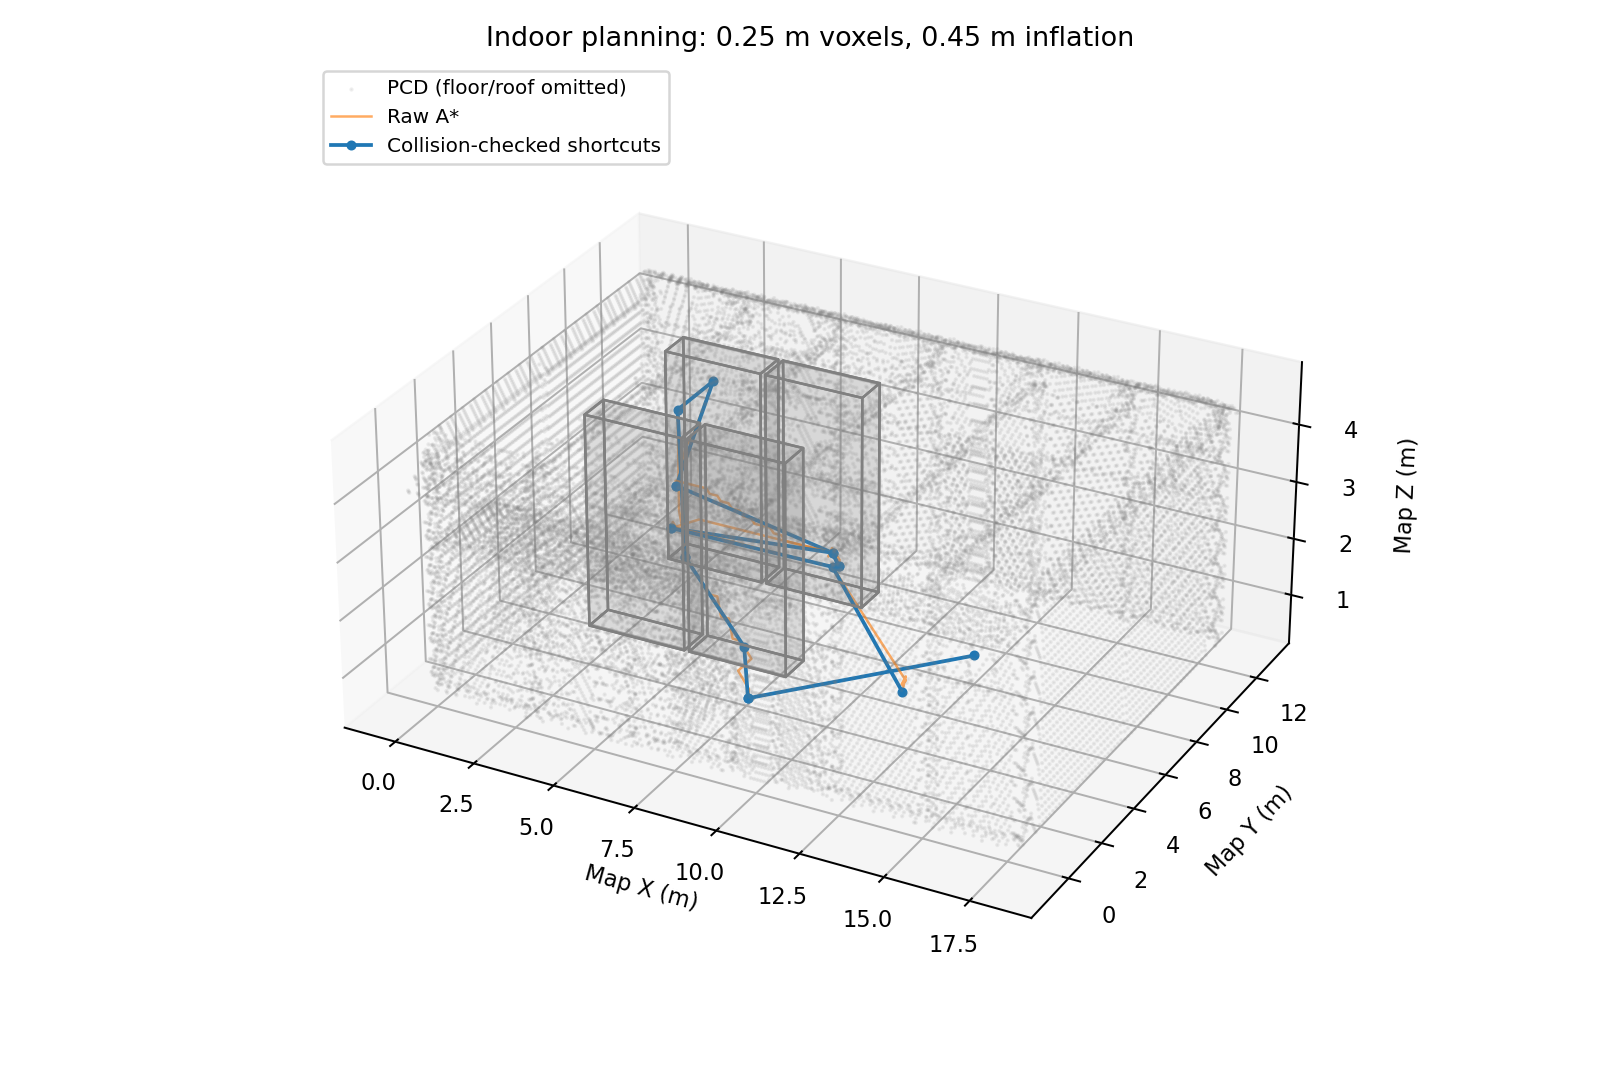

In [3]:
figure("planning_3d.png")

In [4]:
rows = metrics["planning"]
table(["Úsek CSV", "Body A* → po skrátení", "Medián času (ms)", "Dĺžka (m)", "Kolízna kontrola"], [
    [f"W{p['leg']-1} → W{p['leg']}", f"{p['raw_points']} → {p['simplified_points']}",
     number(1000 * p["median_seconds"], 2), number(p["length_m"], 2), p["collision_free"]]
    for p in rows
])
raw = sum(p["raw_points"] for p in rows)
simplified = sum(p["simplified_points"] for p in rows)
print(f"Body cez všetky úseky: {raw} → {simplified}; zníženie o {number(100 * (1 - simplified/raw), 1)} %")

| Úsek CSV | Body A* → po skrátení | Medián času (ms) | Dĺžka (m) | Kolízna kontrola |
| --- | --- | --- | --- | --- |
| W0 → W1 | 2 → 2 | 0,33 | 6,61 | True |
| W1 → W2 | 17 → 3 | 11,64 | 5,42 | True |
| W2 → W3 | 27 → 4 | 56,53 | 8,43 | True |
| W3 → W4 | 27 → 3 | 29,34 | 7,54 | True |
| W4 → W5 | 24 → 3 | 5,58 | 6,55 | True |
| W5 → W6 | 45 → 3 | 30,68 | 13,74 | True |

Body cez všetky úseky: 142 → 18; zníženie o 87,3 %


Čas je medián troch nových behov na rovnakom stroji, vrátane skrátenia a
kontroly segmentov, bez načítania PCD. Prvý úsek má voľnú priamu viditeľnosť,
preto nepotrebuje prehľadávanie A*. Všetky výsledné segmenty prešli kolíznou
kontrolou v nafúknutej mape. Súčet bodov cez šesť úsekov klesol zo 142 na 18
(spoločné koncové body sú v tomto súčte započítané pre každý úsek).

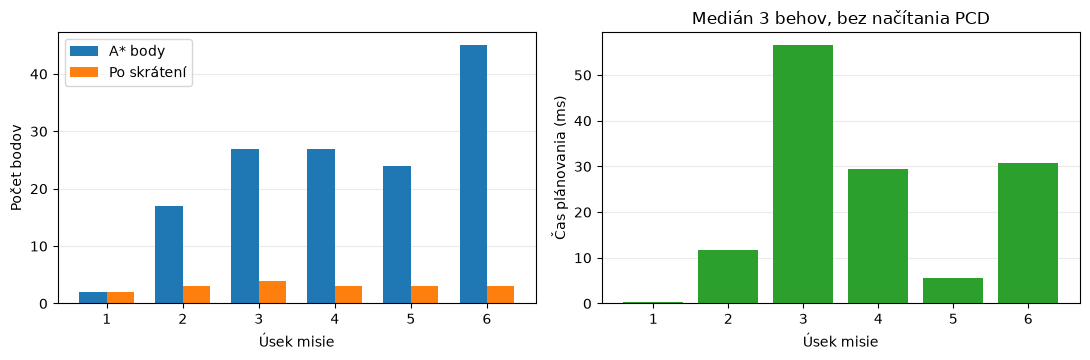

In [5]:
legs = [p["leg"] for p in metrics["planning"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].bar([i - 0.18 for i in legs], [p["raw_points"] for p in metrics["planning"]],
            width=0.36, label="A* body")
axes[0].bar([i + 0.18 for i in legs], [p["simplified_points"] for p in metrics["planning"]],
            width=0.36, label="Po skrátení")
axes[0].set(xlabel="Úsek misie", ylabel="Počet bodov", xticks=legs)
axes[0].legend()
axes[1].bar(legs, [1000*p["median_seconds"] for p in metrics["planning"]], color="tab:green")
axes[1].set(xlabel="Úsek misie", ylabel="Čas plánovania (ms)", xticks=legs,
            title="Medián 3 behov, bez načítania PCD")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

[Graf počtu bodov a časov plánovania](figures/planning_stats.png)
([PDF](figures/planning_stats.pdf)). Časy sa pri opakovaní menia podľa záťaže.

## 2. Vnútorný let

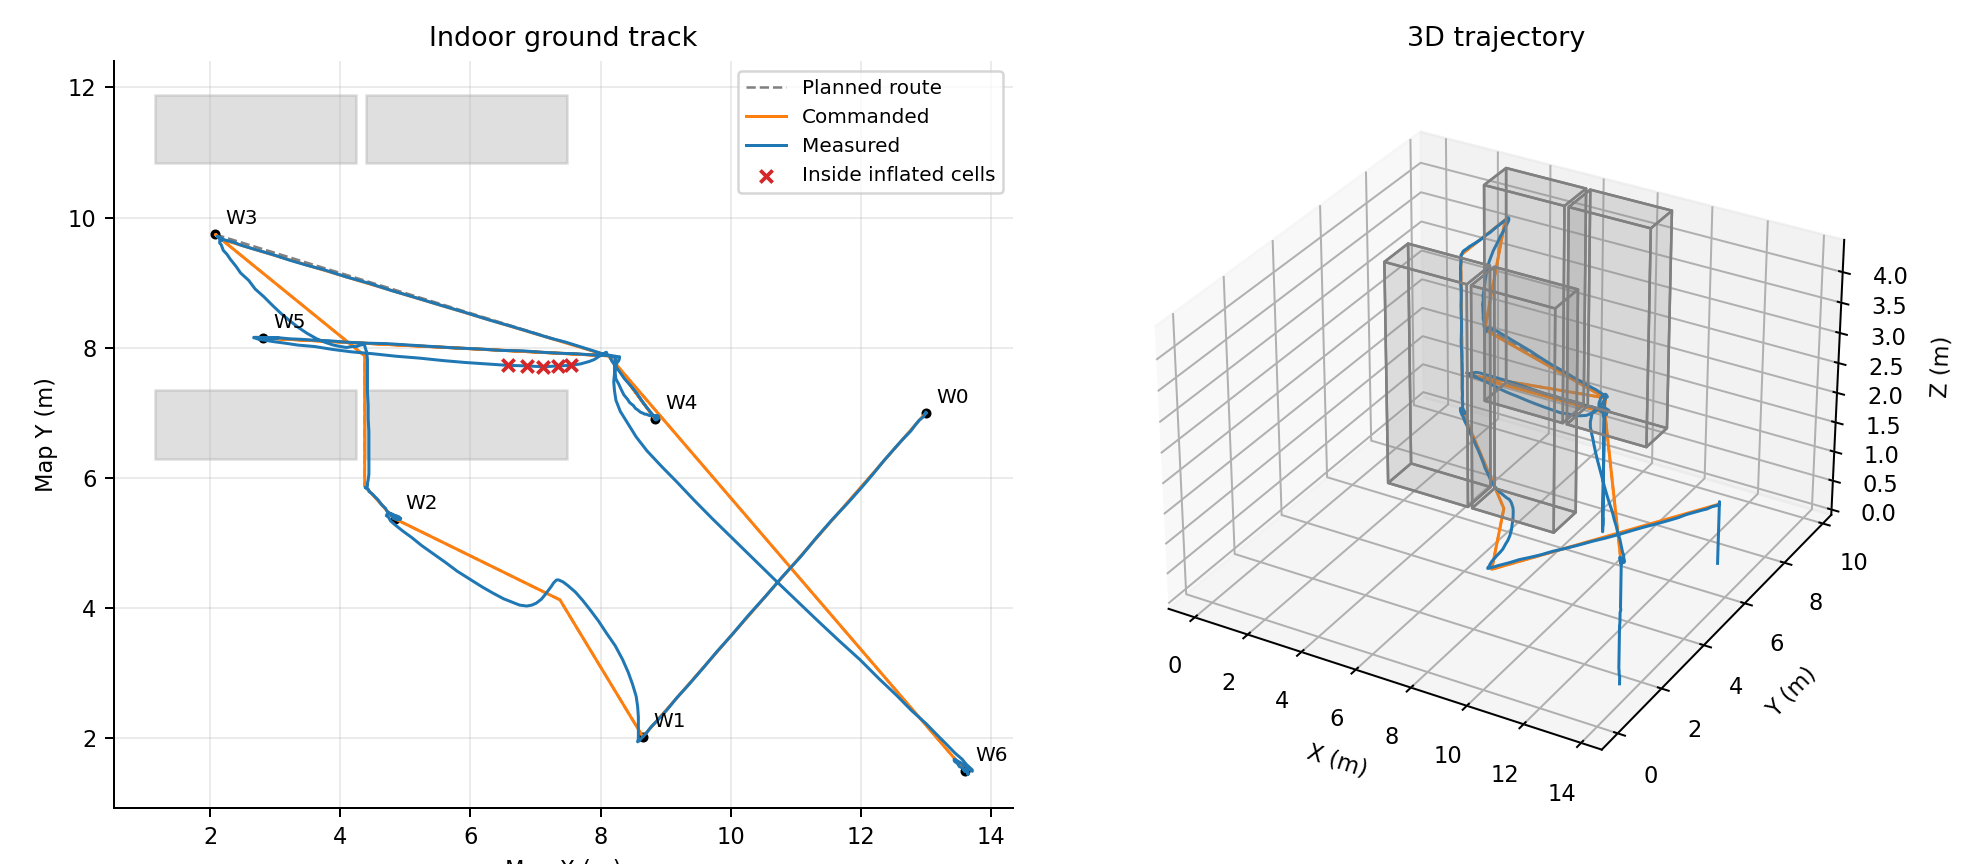

In [6]:
figure("indoor_track.png")

Poloha MAVROS je pre graf prevedená späť do mapy inverznou rotáciou 90° a
posunom kalibrovaným zo zaznamenanej polohy pred vzletom pri mapovom štarte
`(13, 7, 0)`. W0 až W6 označujú riadky CSV. Graf výšky potvrdzuje dva vzlety
a dve pristátia; graf yaw zachytáva otočenia aj prechod cez ±180°.

In [7]:
indoor = metrics["indoor"]
distance = indoor["navigation_path_distance_m"]
clearance = indoor["navigation_clearance"]
hard_errors = [p["error_m"] for p in indoor["waypoint_arrivals"] if p["precision"] == "hard"]
table(["Meranie počas NAVIGATE", "Hodnota"], [
    ["Počet vzoriek", clearance["samples"]],
    ["Vzdialenosť od plánovanej trasy — medián", number(distance["median"]) + " m"],
    ["Vzdialenosť — 95. percentil / maximum", f"{number(distance['p95'])} / {number(distance['maximum'])} m"],
    ["Najväčšia odchýlka pri príchode na hard bod", number(max(hard_errors)) + " m"],
    ["Vzorky v pôvodných obsadených voxeloch", clearance["inside_occupied_voxels"]],
    ["Vzorky v nafúknutých voxeloch", clearance["inside_inflated_voxels"]],
])

| Meranie počas NAVIGATE | Hodnota |
| --- | --- |
| Počet vzoriek | 392 |
| Vzdialenosť od plánovanej trasy — medián | 0,072 m |
| Vzdialenosť — 95. percentil / maximum | 0,365 / 0,612 m |
| Najväčšia odchýlka pri príchode na hard bod | 0,117 m |
| Vzorky v pôvodných obsadených voxeloch | 0 |
| Vzorky v nafúknutých voxeloch | 5 |

**Limit sledovania trasy:** dron pri zrezaní zákruty prešiel bezpečnostným
okolím regálu, hoci zostal mimo pôvodných obsadených voxelov. Červené krížiky
označujú tieto vzorky. Kolízna kontrola plánovaných úsečiek preto nezaručuje,
že skutočný let vždy dodrží celú rezervu 0,45 m. Prispieva k tomu priebežná
akceptácia bodov do 0,35 m a dynamika polohového regulátora. Pre lepšie
dodržanie odstupu treba overiť spomaľovanie alebo menšiu toleranciu pri rohoch.
Kontrola diskrétnych vzoriek sama osebe nedokazuje bezkolíznosť celého pohybu.

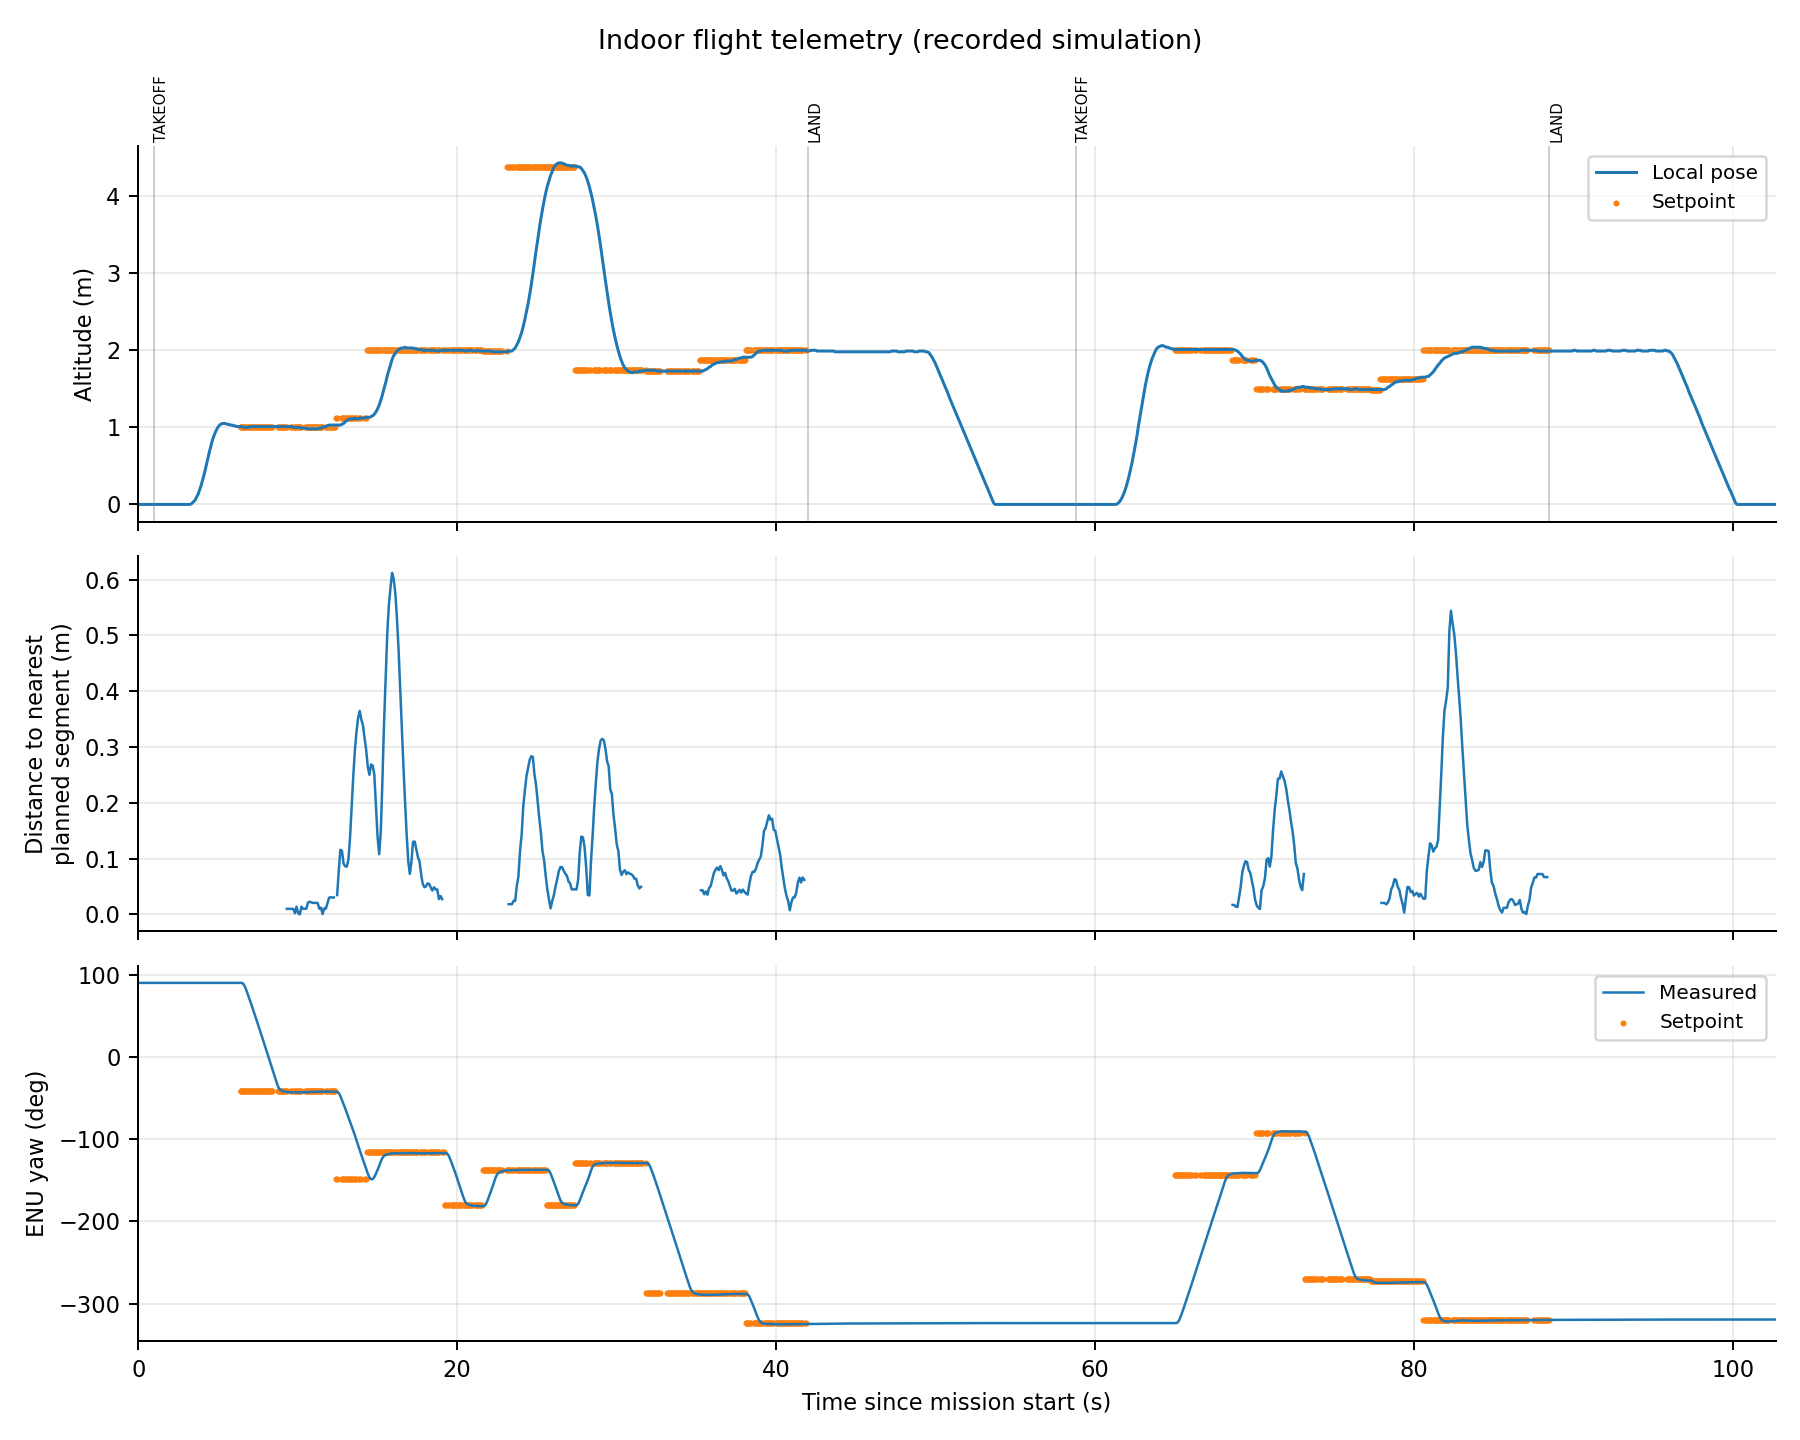

In [8]:
figure("indoor_tracking.png")

[Výška, vzdialenosť od trasy a yaw v čase](figures/indoor_tracking.png)
([PDF](figures/indoor_tracking.pdf)). Odstup sa počíta od najbližšieho segmentu
celej plánovanej misie, nie od časovo priradeného segmentu. Vyhodnocuje sa iba
v `NAVIGATE`; pristávanie a vzlet sú z tejto metriky vynechané. Odchýlka pri
príchode používa najbližšiu vzorku polohy k udalosti `TASK`.

## 3. Vonkajší let

Parametre: strana štvorca 5 m, výška nad štartom 5 m, POI pri home,
`square_speed=0.30 m/s`, `A=3 m`, `omega=0.12 rad/s`, deklinácia 0°.

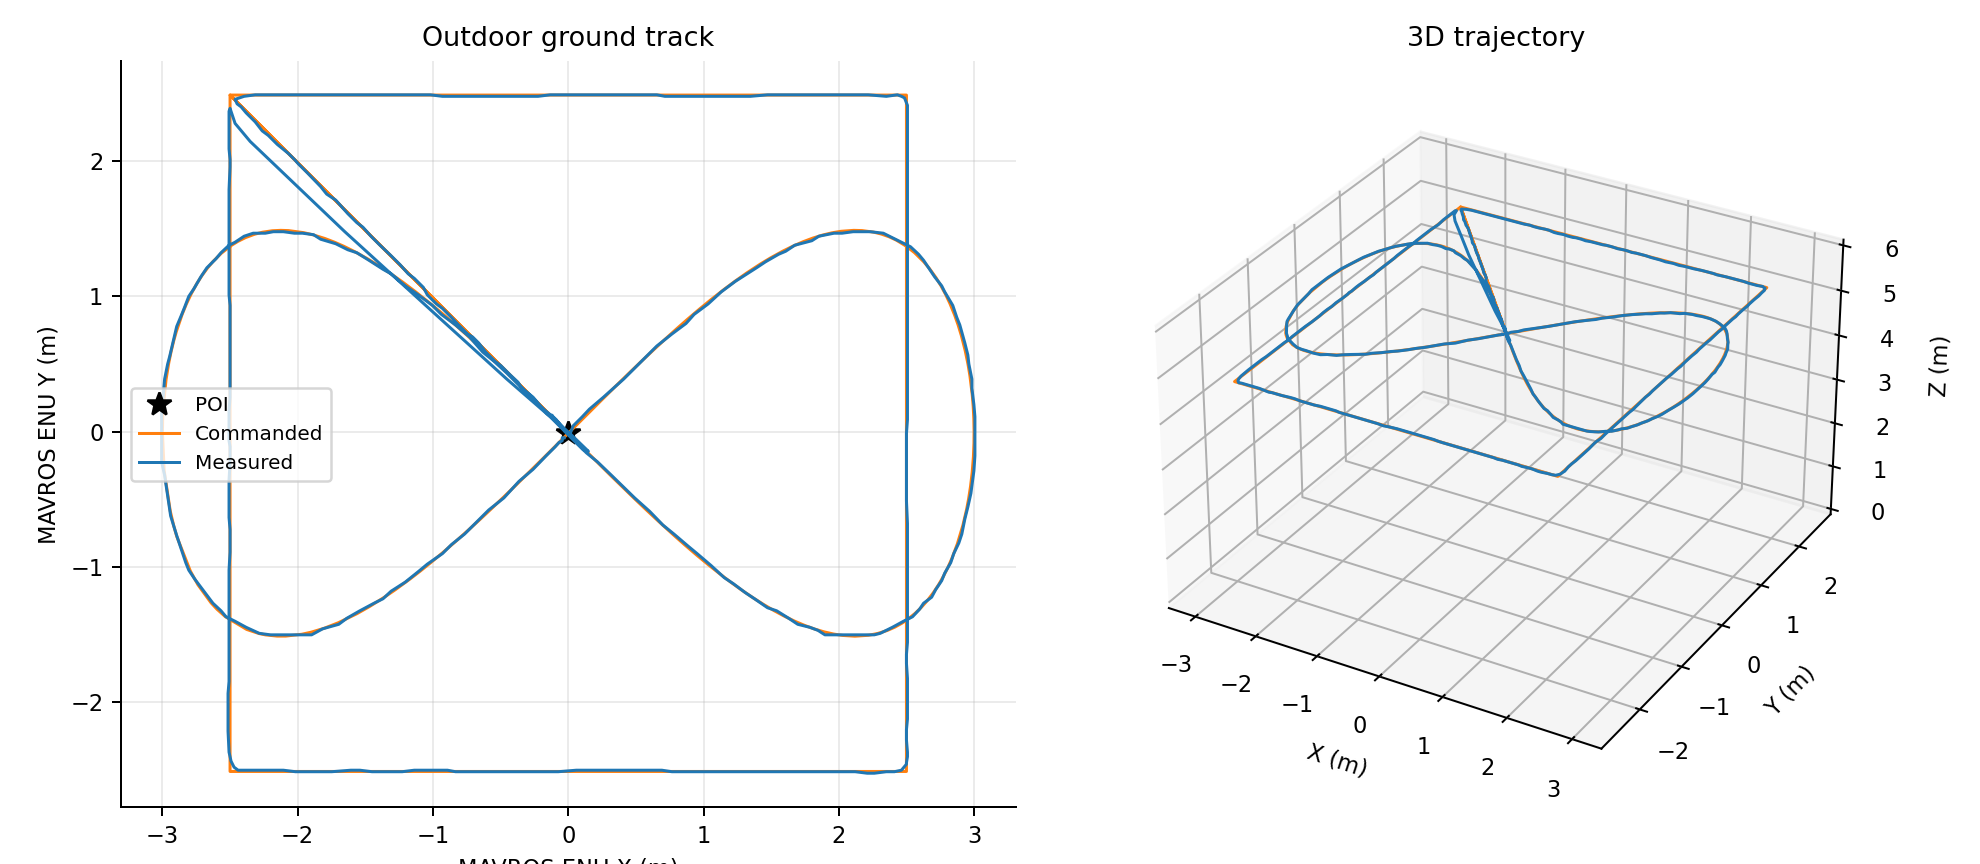

In [9]:
figure("outdoor_track.png")

Zo zaznamenaných príkazov bolo overené poradie rohov **W1 → W2 → W3 → W4 →
W1**. Uzavretie štvrtej strany je teda súčasťou aktuálneho záznamu. Potom dron
preletel do stredu a vykonal osmičku za **52,35 s**. Najväčší nameraný
vodorovný odstup od POI bol **3,511 m**; plánovaná hranica je 3,536 m.
Vonkajší 3D graf zobrazuje fázy publikované cez `Path`; vzlet a pristátie sú
viditeľné v časovom grafe výšky.

In [10]:
outdoor = metrics["outdoor"]
measurements = [
    ("Štvorec: vzdialenosť od súčasného setpointu", "square_tracking_m", "m", 3),
    ("Osmička: vzdialenosť od súčasného setpointu", "figure_eight_tracking_m", "m", 3),
    ("Štvorec: absolútna chyba yaw na POI", "square_yaw_error_deg", "°", 2),
    ("Osmička: absolútna chyba yaw na dotyčnicu", "figure_eight_yaw_error_deg", "°", 2),
]
table(["Meranie", "Medián", "95. percentil", "Maximum"], [
    [label, *[number(outdoor[key][stat], digits) + " " + unit for stat in ("median", "p95", "maximum")]]
    for label, key, unit, digits in measurements
])
print("Poradie rohov:", " → ".join(f"W{i}" for i in outdoor["square_corner_order"]))
print("Trvanie osmičky:", number(outdoor["figure_eight_duration_s"], 2), "s")

| Meranie | Medián | 95. percentil | Maximum |
| --- | --- | --- | --- |
| Štvorec: vzdialenosť od súčasného setpointu | 0,336 m | 0,367 m | 0,462 m |
| Osmička: vzdialenosť od súčasného setpointu | 0,385 m | 0,548 m | 0,589 m |
| Štvorec: absolútna chyba yaw na POI | 0,57 ° | 1,42 ° | 2,57 ° |
| Osmička: absolútna chyba yaw na dotyčnicu | 1,29 ° | 4,63 ° | 13,09 ° |

Poradie rohov: W1 → W2 → W3 → W4 → W1
Trvanie osmičky: 52,35 s


Pri pohyblivej trajektórii vzdialenosť od súčasného setpointu zachytáva aj
časové oneskorenie dronu. Preto sa môže pôdorysná stopa dobre prekrývať, aj
keď táto metrika nie je nulová. Prechod zo štvorca na stred používa skok
cielovej polohy a v celkovom grafe krátko dosiahne približne 3,47 m.

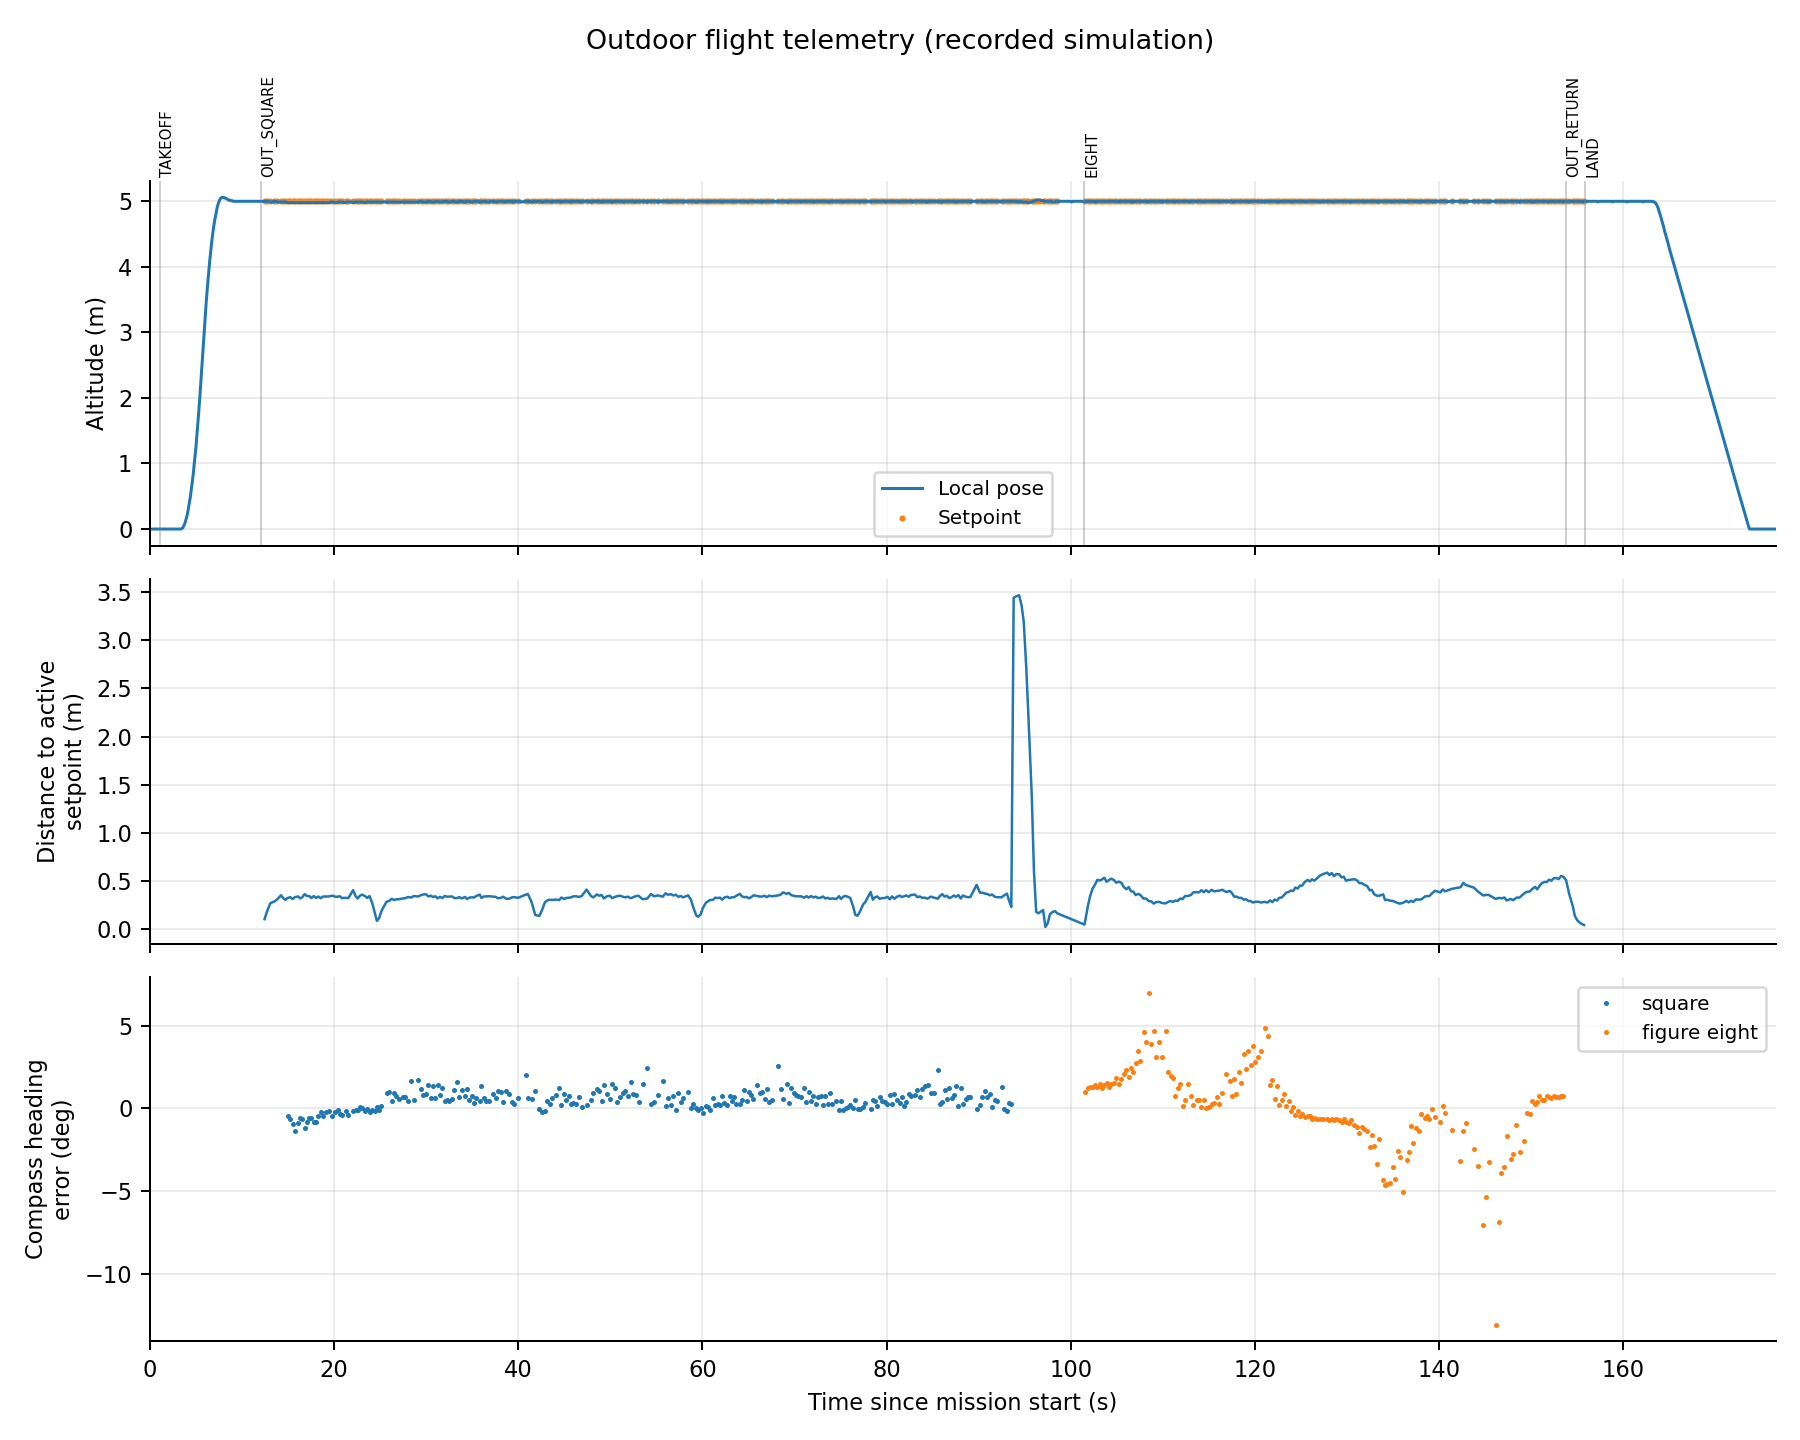

In [11]:
figure("outdoor_tracking.png")

[Výška, chyba polohy a chyba natočenia v čase](figures/outdoor_tracking.png)
([PDF](figures/outdoor_tracking.pdf)). Časovač je nastavený na 20 Hz; v tomto
zázname vyšla priemerná frekvencia publikovania **17,02 Hz**, medián intervalu
50 ms, 95. percentil 122 ms a maximum 650 ms. Python executor a zdieľané
prostredie neposkytujú garanciu dodržania každej periódy.

## 4. Prerušenie misie

Počas ďalšieho letu bola zavolaná služba `/assignment1_outdoor/abort`.
Odpoveď mala `success=True`, node prešiel do `ABORT` a prvá nasledujúca správa
autopilota hlásila RTL približne po **0,060 s**. Po prerušení neboli
zaznamenané ďalšie setpointy; kontrola pripúšťa 50 ms na poradie doručenia
správ. Autopilot sa vrátil a pristál, posledný stav mal `armed=False`.

RTL sa riadi parametrami autopilota: pri tomto teste dosiahlo výšku 8,86 m.
Limit 6 m v našom node kontroluje geometriu plánovanej misie pred štartom;
nie je aktívnou výškovou bariérou pre RTL.

[Záznam, odpoveď služby a namerané hodnoty](../../assignment1_mission/evidence/abort/).

In [12]:
table(["Kontrola prerušenia", "Nameraná hodnota"], [
    ["Odpoveď služby success", abort["service_success"]],
    ["Stav node / konečný režim autopilota", f"{abort['controller_state']} / {abort['final_mode']}"],
    ["Čas po prvú správu RTL", number(abort["response_to_rtl_s"]) + " s"],
    ["Setpointy po prerušení (tolerancia 50 ms)", abort["setpoints_after_abort"]],
    ["Konečný stav armed", abort["final_armed"]],
    ["Maximálna lokálna výška pri RTL", number(abort["maximum_local_altitude_m"], 2) + " m"],
])

| Kontrola prerušenia | Nameraná hodnota |
| --- | --- |
| Odpoveď služby success | True |
| Stav node / konečný režim autopilota | ABORT / RTL |
| Čas po prvú správu RTL | 0,060 s |
| Setpointy po prerušení (tolerancia 50 ms) | 0 |
| Konečný stav armed | False |
| Maximálna lokálna výška pri RTL | 8,86 m |

## Dáta a zopakovanie grafov

- [Vnútorný rosbag, log a parametre](../../assignment1_mission/evidence/indoor/).
- [Vonkajší rosbag, log a parametre](../../assignment1_mission/evidence/outdoor/).
- [Presné hodnoty a udalosti](figures/metrics.json).
- [Prostredie a SHA-256 použitých zdrojov](RUN.json).
- [Postup záznamu](../../assignment1_mission/evidence/README.md).

Po zostavení balíka spusti z koreňa repozitára:

```bash
source install/setup.bash
/usr/bin/python3 assignment1_mission/tools/plot_evidence.py \
  --indoor assignment1_mission/evidence/indoor \
  --outdoor assignment1_mission/evidence/outdoor \
  --output assignment1_parts/04_documentation_and_defence/figures
```

Skript potrebuje systémový Matplotlib a `rosbag2_py` z ROS Jazzy. Vytvorí šesť
grafov v PNG/PDF a `metrics.json`. Je určený pre uvedený CSV súbor a predvolené
rozmery misie. Číta rosbagy priamo zo súborov; neprehráva letové príkazy.

Vonkajšia poloha pochádza z posledných kompletných histórií `Path` (480 párov
s rovnakým časom). Yaw používa najbližší kompasový záznam s rozdielom času
do 0,3 s; pri štvorci sú vynechané polohy bližšie ako 0,5 m od POI, kde je
smer na POI neurčitý. Pri kompasových a stavových správach sa používa čas
prijatia v rosbagu, pri bodoch `Path` ich časová značka. Rozdiely uhlov sú
normalizované do ±180°. Výsledky platia pre simuláciu bez pridaného vetra
a senzorového šumu nad štandardné nastavenie SITL.

## Parametre osmičky a číselné overenie

Nasledujúca bunka porovná teoretické trvanie a rýchlosť z parametrov
nameranej misie s výsledkom záznamu. Rovnice sú $x=A\sin(\omega t)$ a
$y=A\sin(\omega t)\cos(\omega t)$, preto $T=2\pi/\omega$ a
$v_{max}=A\omega\sqrt{2}$.

In [13]:
A = 3.0
omega = 0.12
period = 2 * math.pi / omega
v_max = A * omega * math.sqrt(2)
table(["Veličina", "Hodnota"], [
    ["Teoretický čas osmičky", number(period, 2) + " s"],
    ["Nameraný čas osmičky", number(metrics["outdoor"]["figure_eight_duration_s"], 2) + " s"],
    ["Teoretická maximálna rýchlosť", number(v_max) + " m/s"],
    ["Priemerná frekvencia publikovania zo záznamu", number(run["outdoor_publication"]["mean_hz"], 2) + " Hz"],
])

| Veličina | Hodnota |
| --- | --- |
| Teoretický čas osmičky | 52,36 s |
| Nameraný čas osmičky | 52,35 s |
| Teoretická maximálna rýchlosť | 0,509 m/s |
| Priemerná frekvencia publikovania zo záznamu | 17,02 Hz |